In [ ]:
#works with multichannels

In [1]:
import tensorflow as tf
import numpy as np
from PIL import Image
import rasterio
import imgaug as ia
from imgaug import augmenters as iaa
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import imageio
import os
import time
import rasterio.warp             # Reproject raster samples
from functools import reduce
from tensorflow.keras.models import load_model

from core.UNet import UNet
from core.losses import tversky, accuracy, dice_coef, dice_loss, specificity, sensitivity
from core.optimizers import adaDelta, adagrad, adam, nadam
from core.frame_info import FrameInfo
from core.dataset_generator import DataGenerator
from core.split_frames import split_dataset
from core.visualize import display_images

import json
from sklearn.model_selection import train_test_split

%matplotlib inline
import matplotlib.pyplot as plt  # plotting tools
import matplotlib.patches as patches
from matplotlib.patches import Polygon

import warnings                  # ignore annoying warnings
warnings.filterwarnings("ignore")
import logging
logger = logging.getLogger()
logger.setLevel(logging.CRITICAL)

%reload_ext autoreload
%autoreload 2
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

print(tf.__version__)

2021-10-10 15:30:48.181608: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0


2.5.0-dev20201225


In [2]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2021-10-10 15:31:02.947585: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcuda.so.1
2021-10-10 15:31:02.991592: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:941] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2021-10-10 15:31:02.992339: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1760] Found device 0 with properties: 
pciBusID: 0000:21:00.0 name: NVIDIA GeForce RTX 3090 computeCapability: 8.6
coreClock: 1.695GHz coreCount: 82 deviceMemorySize: 23.70GiB deviceMemoryBandwidth: 871.81GiB/s
2021-10-10 15:31:02.992355: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0
2021-10-10 15:31:03.007603: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcublas.so.11
2021-10-10 15:31:03.007653: I tensorflow/stream_executor/pl

In [3]:
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)

In [3]:
# Required configurations (including the input and output paths) are stored in a separate file (such as config/UNetTraining.py)
# Please provide required info in the file before continuing with this notebook. 
 
from config import UNetTraining
# In case you are using a different folder name such as configLargeCluster, then you should import from the respective folder 
# Eg. from configLargeCluster import UNetTraining
config = UNetTraining.Configuration()

In [4]:
# Read all images/frames into memory
frames = []

all_files = os.listdir(config.base_dir)
# image channel 1
all_files_c1 = [fn for fn in all_files if fn.startswith(config.extracted_filenames[0]) and fn.endswith(config.image_type)]
print(all_files_c1)
#all_files_c1: [c1_0.png, c1_1.png, c1_2.png,...]

['blue_59.png', 'blue_313.png', 'blue_320_2000.png', 'blue_171_2000.png', 'blue_0_2017.png', 'blue_295_2000.png', 'blue_441.png', 'blue_416_2000.png', 'blue_465_2000.png', 'blue_301.png', 'blue_545.png', 'blue_143_2000.png', 'blue_361.png', 'blue_447_2000.png', 'blue_34.png', 'blue_10_2016.png', 'blue_93.png', 'blue_431.png', 'blue_6.png', 'blue_408.png', 'blue_170.png', 'blue_15_2018.png', 'blue_290_2000.png', 'blue_106.png', 'blue_317_2000.png', 'blue_474_2000.png', 'blue_425.png', 'blue_393.png', 'blue_269_2000.png', 'blue_354.png', 'blue_8_2000.png', 'blue_296.png', 'blue_494_2000.png', 'blue_66_2000.png', 'blue_16_2016.png', 'blue_469_2000.png', 'blue_563.png', 'blue_299.png', 'blue_172.png', 'blue_85_2000.png', 'blue_619.png', 'blue_11_2018.png', 'blue_162.png', 'blue_378_2000.png', 'blue_79.png', 'blue_76.png', 'blue_132.png', 'blue_159_2000.png', 'blue_115.png', 'blue_81_2000.png', 'blue_4_2020.png', 'blue_521.png', 'blue_493_2000.png', 'blue_18_2018.png', 'blue_294.png', 'blue

In [5]:
for i, fn in enumerate(all_files_c1):
    # loop through rectangles

    comb_img = rasterio.open(os.path.join(config.base_dir, fn)).read()
    
    for c in range(config.image_channels-1):
        #loop through channels
        comb_img = np.append(comb_img, rasterio.open(os.path.join(config.base_dir, fn.replace(config.extracted_filenames[0],config.extracted_filenames[c+1]))).read(), axis = 0)
    
    comb_img = np.transpose(comb_img, axes=(1,2,0)) #Channel at the end
    annotation_im = Image.open(os.path.join(config.base_dir, fn.replace(config.extracted_filenames[0],config.annotation_fn)))
    annotation = np.array(annotation_im)
    weight_im = Image.open(os.path.join(config.base_dir, fn.replace(config.extracted_filenames[0],config.weight_fn)))
    weight = np.array(weight_im)
    f = FrameInfo(comb_img, annotation, weight)
    frames.append(f)

In [6]:
# training_frames, validation_frames, testing_frames  = split_dataset(frames, config.frames_json, config.patch_dir)
training_frames = validation_frames = testing_frames  = list(range(len(frames)))

annotation_channels = config.input_label_channel + config.input_weight_channel
train_generator = DataGenerator(config.input_image_channel, config.patch_size, training_frames, frames, config.label_weight_channel, augmenter = 'iaa').random_generator(config.BATCH_SIZE, normalize = config.normalize)
val_generator = DataGenerator(config.input_image_channel, config.patch_size, validation_frames, frames, config.label_weight_channel, augmenter= None).random_generator(config.BATCH_SIZE, normalize = config.normalize)
test_generator = DataGenerator(config.input_image_channel, config.patch_size, testing_frames, frames, config.label_weight_channel, augmenter= None).random_generator(config.BATCH_SIZE, normalize = config.normalize)

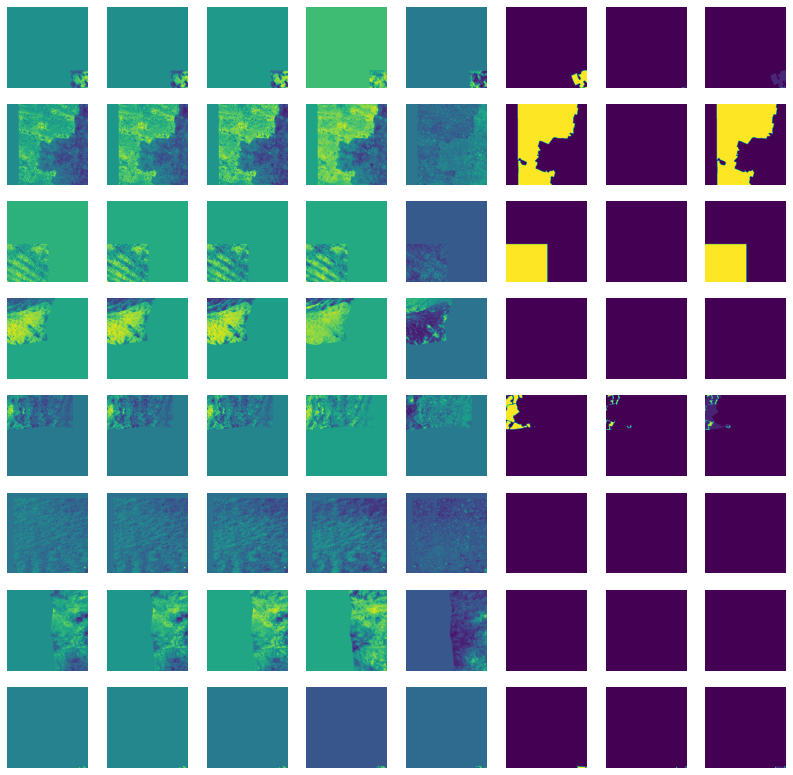

In [7]:
for _ in range(1):
    train_images, real_label = next(train_generator)
    ann = real_label[:,:,:,0]
    wei = real_label[:,:,:,1]
    #overlay of annotation with boundary to check the accuracy
    #8 images in each row are: pan, ndvi, annotation, weight(boundary), overlay of annotation with weight
    overlay = ann + wei
    overlay = overlay[:,:,:,np.newaxis]
    display_images(np.concatenate((train_images,real_label, overlay), axis = -1))

In [8]:
OPTIMIZER = adaDelta
LOSS = tversky 

#Only for the name of the model in the very end
OPTIMIZER_NAME = 'AdaDelta'
LOSS_NAME = 'weightmap_tversky'

# Declare the path to the final model
# If you want to retrain an exising model then change the cell where model is declared. 
# This path is for storing a model after training.

timestr = time.strftime("%Y%m%d-%H%M")
# chf = config.input_image_channel + config.input_label_channel
# chs = reduce(lambda a,b: a+str(b), chf, '')
chs = reduce(lambda a,b: a+str(b), config.input_image_channel, '')


if not os.path.exists(config.model_path):
    os.makedirs(config.model_path)
model_path = os.path.join(config.model_path,'crop_{}_{}_{}_{}_{}.h5'.format(timestr,OPTIMIZER_NAME,LOSS_NAME,chs,config.input_shape[0]))

# The weights without the model architecture can also be saved. Just saving the weights is more efficent.

# weight_path="./saved_weights/UNet/{}/".format(timestr)
# if not os.path.exists(weight_path):
#     os.makedirs(weight_path)
# weight_path=weight_path + "{}_weights.best.hdf5".format('UNet_model')
# print(weight_path)

In [9]:
# Define the model and compile it
model = UNet([config.BATCH_SIZE, *config.input_shape],config.input_label_channel)
model.compile(optimizer=OPTIMIZER, loss=LOSS, metrics=[dice_coef, dice_loss, specificity, sensitivity, accuracy])

2021-10-10 15:31:52.504580: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2021-10-10 15:31:52.507768: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:941] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2021-10-10 15:31:52.508642: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1760] Found device 0 with properties: 
pciBusID: 0000:21:00.0 name: NVIDIA GeForce RTX 3090 computeCapability: 8.6
coreClock: 1.695GHz coreCount: 82 deviceMemorySize: 23.70GiB deviceMemoryBandwidth: 871.81GiB/s
2021-10-10 15:31:52.508672: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0
20

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
Input (InputLayer)              [(None, 512, 512, 5) 0                                            
__________________________________________________________________________________________________
conv2d (Conv2D)                 (None, 512, 512, 64) 2944        Input[0][0]                      
__________________________________________________________________________________________________
conv2d_1 (Conv2D)               (None, 512, 512, 64) 36928       conv2d[0][0]                     
__________________________________________________________________________________________________
batch_normalization (BatchNorma (None, 512, 512, 64) 256         conv2d_1[0][0]                   
______________________________________________________________________________________________

In [10]:
# Define callbacks for the early stopping of training, LearningRateScheduler and model checkpointing
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler, EarlyStopping, ReduceLROnPlateau, TensorBoard


checkpoint = ModelCheckpoint(model_path, monitor='val_loss', verbose=1, 
                             save_best_only=True, mode='min', save_weights_only = False)

#reduceonplatea; It can be useful when using adam as optimizer
#Reduce learning rate when a metric has stopped improving (after some patience,reduce by a factor of 0.33, new_lr = lr * factor).
#cooldown: number of epochs to wait before resuming normal operation after lr has been reduced.
reduceLROnPlat = ReduceLROnPlateau(monitor='val_loss', factor=0.33,
                                   patience=4, verbose=1, mode='min',
                                   min_delta=0.0001, cooldown=4, min_lr=1e-16)

#early = EarlyStopping(monitor="val_loss", mode="min", verbose=2, patience=15)

log_dir = os.path.join('./logs','UNet_{}_{}_{}_{}_{}'.format(timestr,OPTIMIZER_NAME,LOSS_NAME,chs, config.input_shape[0]))
tensorboard = TensorBoard(log_dir=log_dir, histogram_freq=0, write_graph=True, write_grads=False, write_images=False, embeddings_freq=0, embeddings_layer_names=None, embeddings_metadata=None, embeddings_data=None, update_freq='epoch')

callbacks_list = [checkpoint, tensorboard] #reduceLROnPlat is not required with adaDelta

2021-10-10 15:31:59.252699: I tensorflow/core/profiler/lib/profiler_session.cc:126] Profiler session initializing.
2021-10-10 15:31:59.252728: I tensorflow/core/profiler/lib/profiler_session.cc:141] Profiler session started.
2021-10-10 15:31:59.253902: I tensorflow/core/profiler/internal/gpu/cupti_tracer.cc:1594] Profiler found 1 GPUs
2021-10-10 15:31:59.254192: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcupti.so.11.0'; dlerror: libcupti.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/lib/cuda/include:/usr/lib/cuda/lib64:
2021-10-10 15:31:59.261521: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcupti.so
2021-10-10 15:31:59.403026: I tensorflow/core/profiler/lib/profiler_session.cc:158] Profiler session tear down.
2021-10-10 15:31:59.404881: I tensorflow/core/profiler/internal/gpu/cupti_tracer.cc:1726] CUPTI activity buffer flushed


In [ ]:
tf.config.run_functions_eagerly(True)

In [ ]:
%reload_ext tensorboard
%tensorboard --logdir log_dir

In [ ]:
loss_history = [model.fit(train_generator, 
                         steps_per_epoch=config.MAX_TRAIN_STEPS, 
                         epochs=config.NB_EPOCHS, 
                         validation_data=val_generator,
                         validation_steps=config.VALID_IMG_COUNT,
                         callbacks=callbacks_list,
                         workers=1,
#                         use_multiprocessing=True # the generator is not very thread safe
                        )]

2021-10-10 15:32:09.055474: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:127] None of the MLIR optimization passes are enabled (registered 2)
2021-10-10 15:32:09.076215: I tensorflow/core/platform/profile_utils/cpu_utils.cc:112] CPU Frequency: 3700295000 Hz


Epoch 1/200


2021-10-10 15:32:10.581512: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudnn.so.8
2021-10-10 15:32:11.717387: I tensorflow/stream_executor/cuda/cuda_dnn.cc:334] Loaded cuDNN version 8204
2021-10-10 15:32:13.218037: W tensorflow/stream_executor/gpu/asm_compiler.cc:64] Running ptxas --version returned 256
2021-10-10 15:32:13.297486: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] Internal: ptxas exited with non-zero error code 256, output: 
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.
2021-10-10 15:32:13.418318: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcublas.so.11
2021-10-10 15:32:14.258452: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcublasLt.so.11


  1/500 [..............................] - ETA: 1:56:34 - loss: 0.9473 - dice_coef: 0.0254 - dice_loss: 0.9746 - specificity: 0.0154 - sensitivity: 0.9631 - accuracy: 0.0436

2021-10-10 15:32:23.152196: I tensorflow/core/profiler/lib/profiler_session.cc:126] Profiler session initializing.
2021-10-10 15:32:23.152228: I tensorflow/core/profiler/lib/profiler_session.cc:141] Profiler session started.


  2/500 [..............................] - ETA: 8:08 - loss: 0.9500 - dice_coef: 0.0237 - dice_loss: 0.9763 - specificity: 0.0314 - sensitivity: 0.9723 - accuracy: 0.0569   

2021-10-10 15:32:24.089843: I tensorflow/core/profiler/lib/profiler_session.cc:66] Profiler session collecting data.
2021-10-10 15:32:24.092428: I tensorflow/core/profiler/internal/gpu/cupti_tracer.cc:1726] CUPTI activity buffer flushed
2021-10-10 15:32:24.165179: I tensorflow/core/profiler/internal/gpu/cupti_collector.cc:661]  GpuTracer has collected 712 callback api events and 705 activity events. 
2021-10-10 15:32:24.188415: I tensorflow/core/profiler/lib/profiler_session.cc:158] Profiler session tear down.
2021-10-10 15:32:24.207350: I tensorflow/core/profiler/rpc/client/save_profile.cc:137] Creating directory: ./logs/UNet_20211010-1531_AdaDelta_weightmap_tversky_01234_512/train/plugins/profile/2021_10_10_15_32_24
2021-10-10 15:32:24.222388: I tensorflow/core/profiler/rpc/client/save_profile.cc:143] Dumped gzipped tool data for trace.json.gz to ./logs/UNet_20211010-1531_AdaDelta_weightmap_tversky_01234_512/train/plugins/profile/2021_10_10_15_32_24/tong.trace.json.gz
2021-10-10 15:3

500/500 [==============================] - 434s 841ms/step - loss: 0.6427 - dice_coef: 0.3592 - dice_loss: 0.6408 - specificity: 0.8254 - sensitivity: 0.6659 - accuracy: 0.8025 - val_loss: 0.5767 - val_dice_coef: 0.7791 - val_dice_loss: 0.2209 - val_specificity: 0.8328 - val_sensitivity: 0.6821 - val_accuracy: 0.8132

Epoch 00001: val_loss improved from inf to 0.57671, saving model to ./saved_models/UNet/crop_20211010-1531_AdaDelta_weightmap_tversky_01234_512.h5
Epoch 2/200
500/500 [==============================] - 417s 835ms/step - loss: 0.6023 - dice_coef: 0.7831 - dice_loss: 0.2169 - specificity: 0.8567 - sensitivity: 0.6871 - accuracy: 0.8334 - val_loss: 0.6224 - val_dice_coef: 0.7821 - val_dice_loss: 0.2179 - val_specificity: 0.8225 - val_sensitivity: 0.7427 - val_accuracy: 0.8153

Epoch 00002: val_loss did not improve from 0.57671
Epoch 3/200
500/500 [==============================] - 419s 839ms/step - loss: 0.5918 - dice_coef: 0.8192 - dice_loss: 0.1808 - specificity: 0.8732 - 

In [11]:
# Load model after training
# If you load a model with different python version, than you may run into a problem: https://github.com/keras-team/keras/issues/9595#issue-303471777

model = load_model(model_path, custom_objects={'tversky': LOSS, 'dice_coef': dice_coef, 'dice_loss':dice_loss, 'accuracy':accuracy , 'specificity': specificity, 'sensitivity':sensitivity}, compile=False)

# In case you want to use multiple GPU you can uncomment the following lines.
# from tensorflow.python.keras.utils import multi_gpu_model
# model = multi_gpu_model(model, gpus=2, cpu_merge=False)

model.compile(optimizer=OPTIMIZER, loss=LOSS, metrics=[dice_coef, dice_loss, accuracy, specificity, sensitivity])

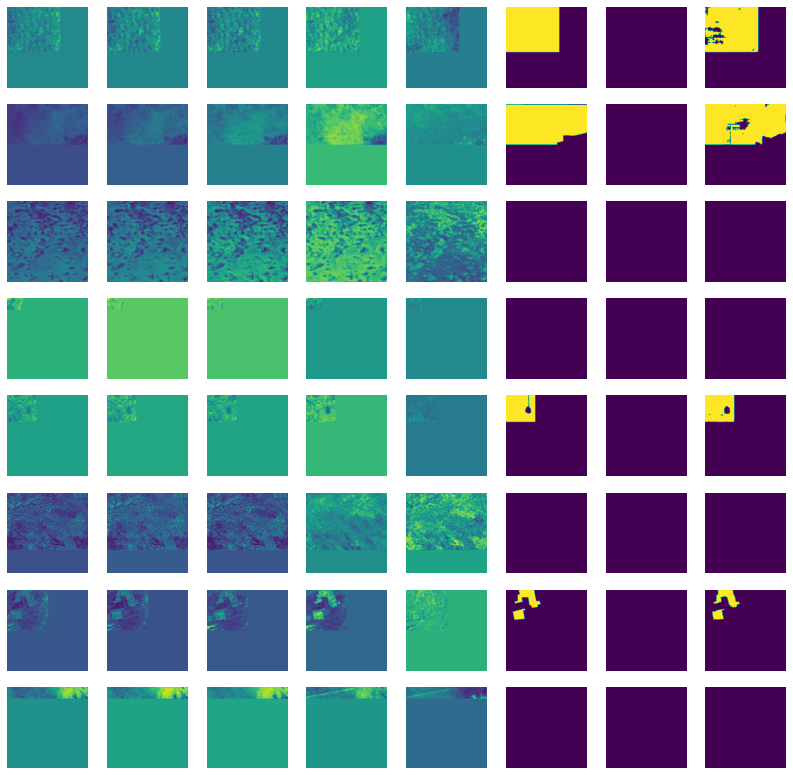

In [16]:
# Print one batch on the training/test data!
for i in range(1):
    test_images, real_label = next(test_generator)
    #5 images per row: pan, ndvi, label, weight, prediction
    prediction = model.predict(test_images, steps=1)
    prediction[prediction>0.5]=1
    prediction[prediction<=0.5]=0
    display_images(np.concatenate((test_images, real_label, prediction), axis = -1))